# ABS Performance Analysis: quantitative research notebook

**All data is simulated.** This notebook explains the end-to-end analysis rather than claiming a real investment track record.

Research questions: How do prepayments and losses affect senior/junior notes? What changes under rate and credit scenarios? Can a constrained allocation reduce measured volatility? Do statistical or ML forecasts beat persistence?

Run `python -m abs_lab.pipeline` first. Every file path is relative to the repository, so the notebook works from either the project root or the notebooks folder.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from abs_lab.data import clean
from abs_lab.cashflows import project, risk_measures
from abs_lab.models import feature_table
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sec, panel, pool, macro, quality = clean(ROOT)
outputs = ROOT / "data/processed"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
display(pd.Series(quality).to_frame("Result"))

,Result
raw_rows,1753
clean_rows,1752
exact_duplicates_removed,1
securities,24
months,73
seed,42
data_type,synthetic


## 1. Source inspection and cleaning

The raw monthly table contains one intentional duplicate. Exact duplicates are removed; conflicting keys and broken balances must fail validation. Macro data is simulated and assumes immediate month-end availability.

In [2]:
raw = pd.read_csv(ROOT / "data/raw/monthly_performance.csv")
print("Raw rows:", len(raw), "Exact duplicates:", raw.duplicated().sum())
display(sec.groupby(["sector", "tranche"]).agg(notes=("security_id", "count"), opening_principal=("initial_balance", "sum")))
assert panel.groupby("security_id").size().eq(73).all()
assert panel.total_return.isna().sum() == 24

Raw rows: 1753 Exact duplicates: 1


notes  opening_principal
sector    tranche                          
Auto      A            4        328000000.0
          B            4         82000000.0
Consumer  A            4        360000000.0
          B            4         90000000.0
Equipment A            4        344000000.0
          B            4         86000000.0

## 2. Sequential waterfall and balance conservation

Collateral pays interest then scheduled principal, prepayments and immediate recoveries. Principal goes to senior A first; losses hit junior B first. This simplified waterfall omits legal triggers, reserve accounts and recovery delays.

,interest,principal,loss
tranche,,,
A,1.019987e+07,8.000000e+07,0.000000e+00
B,1.102173e+07,1.666231e+07,3.337687e+06


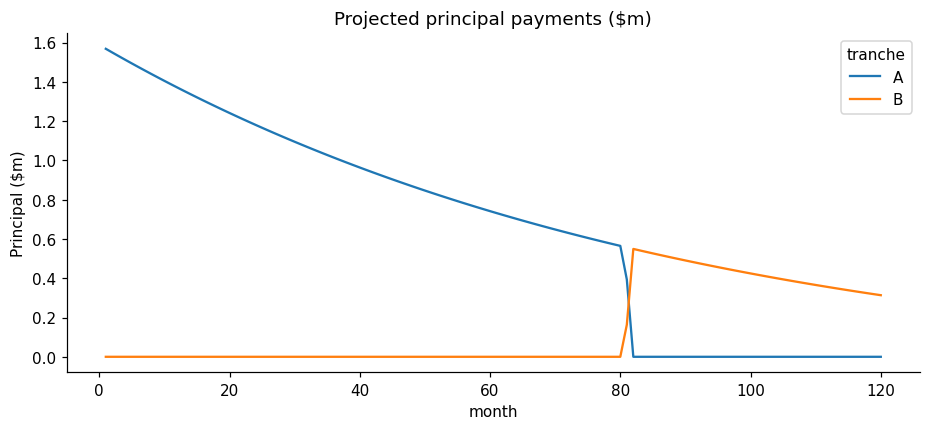

In [3]:
cashflows = project([80_000_000, 20_000_000], [.045, .075], 120, cpr=.08, cdr=.015)
by_note = cashflows.groupby("tranche")[["interest", "principal", "loss"]].sum()
display(by_note)
assert np.isclose(by_note.principal.sum() + by_note.loss.sum(), 100_000_000)
cf = cashflows.pivot(index="month", columns="tranche", values="principal")
cf.div(1e6).plot(title="Projected principal payments ($m)")
plt.ylabel("Principal ($m)")
plt.show()

## 3. Fixed-income valuation and sensitivity

Discount rates are annual effective yields. Duration/convexity keep cash flows fixed; WAL weights principal actually received. They are not OAS or prepayment-option-adjusted risk measures.

In [4]:
rows = []
for tranche, group in cashflows.groupby("tranche"):
    metrics = risk_measures(group.interest + group.principal, group.principal, .055)
    rows.append({"tranche": tranche, **metrics})
display(pd.DataFrame(rows).round(3))

,tranche,pv,duration,convexity,wal
0,A,7.823869e+07,2.433,11.207,2.833
1,B,1.965759e+07,5.865,47.189,8.248


## 4. Monthly total returns

Total return includes both interest and principal distributions. Because credit write-downs affect closing value, subtracting loss again would double count it.

In [5]:
sample = panel[panel.security_id == "DEAL01-A"].copy()
sample["independent_return"] = (sample.market_value + sample.interest + sample.principal) / sample.market_value.shift(1) - 1
assert np.allclose(sample.total_return.iloc[1:], sample.independent_return.iloc[1:])
display(sample[["date", "market_value", "interest", "principal", "loss", "total_return"]].head(8))

,date,market_value,interest,principal,loss,total_return
0,2019-12-31,6.579127e+07,0.000000,0.000000e+00,0.0,NaN
2,2020-01-31,6.424729e+07,240000.000000,1.364095e+06,0.0,0.000914
4,2020-02-29,6.263563e+07,234884.642579,1.310092e+06,0.0,-0.001038
6,2020-03-31,6.138132e+07,229971.796593,1.250938e+06,0.0,0.003618
8,2020-04-30,5.986727e+07,225280.779960,1.277934e+06,0.0,-0.000177
10,2020-05-31,5.836021e+07,220488.526963,1.260944e+06,0.0,-0.000428
12,2020-06-30,5.709182e+07,215759.987348,1.219433e+06,0.0,0.002858
14,2020-07-31,5.567952e+07,211187.112557,1.186314e+06,0.0,-0.000259


## 5. Rules-based ABS index and constrained asset allocation

The index uses prior-month market values. Portfolio weights use only returns known at the decision date. Minimum variance imposes a 15% note cap, 50% sector cap and four-year duration limit. Defensive and Income are demonstration strategies, not real investment managers.

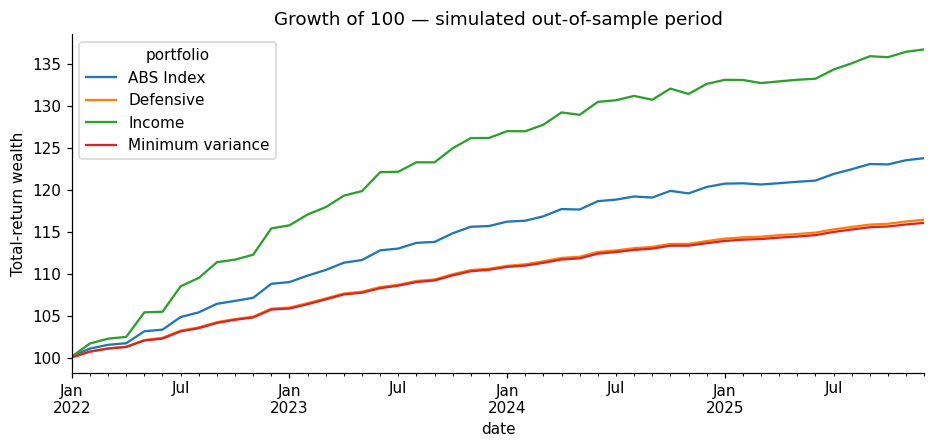

,portfolio,cagr,annual_volatility,max_drawdown,tracking_error,information_ratio,alpha_annualised,beta,alpha_pvalue_hac
0,ABS Index,0.05479,0.01415,-0.00252,0.00000,0.00000,0.00000,1.00000,1.0
1,Defensive,0.03885,0.00722,0.00000,0.00756,-2.03097,0.01209,0.48742,0.0
2,Income,0.08132,0.02709,-0.00483,0.01334,1.89223,-0.02238,1.88907,0.0
3,Minimum variance,0.03801,0.00720,0.00000,0.00766,-2.11192,0.01151,0.48313,0.0


In [6]:
bt = pd.read_csv(outputs / "backtest.csv", parse_dates=["date", "decision_date"])
holdings = pd.read_csv(outputs / "holdings.csv", parse_dates=["date", "decision_date"])
assert (holdings.decision_date < holdings.date).all()
assert np.allclose(holdings.groupby(["date", "portfolio"]).weight.sum(), 1)
assert holdings[holdings.portfolio == "Minimum variance"].weight.max() <= .15001
bt.pivot(index="date", columns="portfolio", values="wealth").plot(title="Growth of 100 — simulated out-of-sample period")
plt.ylabel("Total-return wealth")
plt.show()
display(pd.read_csv(outputs / "manager_evaluation.csv").round(5))

## 6. Client-style mandate inspection

A concrete allocation should include its constraints and trade-offs. The optimized strategy targets low historical volatility, not maximum expected return. It may give up income and underperform the benchmark.

In [7]:
last = holdings[(holdings.date == holdings.date.max()) & (holdings.portfolio == "Minimum variance")]
exposure = last.merge(sec, on="security_id")
display(exposure.groupby("sector").weight.sum().to_frame())
assert exposure.groupby("sector").weight.sum().max() <= .50001
assert bt[bt.portfolio == "Minimum variance"].duration.max() <= 4.00001
print("Latest simulated allocation date:", last.date.iloc[0].date())

Latest simulated allocation date: 2025-12-31


,weight
sector,
Auto,0.396555
Consumer,0.303484
Equipment,0.299962


## 7. Credit and prepayment scenarios

Scenarios reproject cash flows as well as discounting. They are specified shocks, not probabilistic forecasts. Base repricing must reconcile with the snapshot.

tranche,A,B
scenario,,
Base,0.000,-0.000
Credit stress,-0.386,-16.845
Extension,-0.231,-4.299
Fast prepayment,0.128,3.542
Rates +100bp,-0.260,-4.360


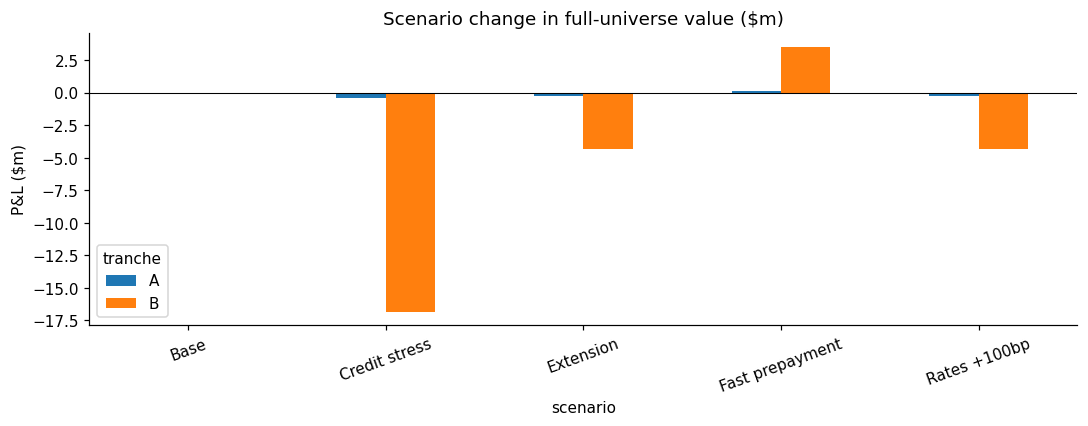

In [8]:
scenarios = pd.read_csv(outputs / "scenarios.csv")
assert np.allclose(scenarios[scenarios.scenario == "Base"].pnl, 0, atol=.2)
summary = scenarios.groupby(["scenario", "tranche"]).pnl.sum().unstack().div(1e6)
display(summary.round(3))
summary.plot.bar(title="Scenario change in full-universe value ($m)")
plt.axhline(0, color="black", linewidth=.7)
plt.ylabel("P&L ($m)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 8. Time-series features and leakage audit

The model predicts next month's equal-deal mean annual CDR from current and lagged information. The training label's target date must be no later than the forecast decision date. In real research, macro publication timestamps and revisions would also matter.

In [9]:
features = feature_table(pool, macro)
display(features.head())
predictions = pd.read_csv(outputs / "predictions.csv", parse_dates=["decision_date", "target_date", "last_training_target_date"])
assert (predictions.last_training_target_date <= predictions.decision_date).all()
assert (predictions.target_date > predictions.decision_date).all()
display(predictions.head(6))

,cdr,unemployment,base_rate,cdr_lag1,cdr_mean3,target,target_date
date,,,,,,,
2020-02-29,0.015282,5.443164,0.027529,0.013009,0.013873,0.015288,2020-03-31
2020-03-31,0.015288,5.631877,0.027317,0.015282,0.014526,0.013931,2020-04-30
2020-04-30,0.013931,5.352279,0.028793,0.015288,0.014834,0.015611,2020-05-31
2020-05-31,0.015611,5.595796,0.030128,0.013931,0.014943,0.016175,2020-06-30
2020-06-30,0.016175,5.946731,0.030035,0.015611,0.015239,0.017353,2020-07-31


,decision_date,target_date,last_training_target_date,model,actual,predicted
0,2023-02-28,2023-03-31,2023-02-28,Persistence,0.008216,0.007294
1,2023-02-28,2023-03-31,2023-02-28,OLS,0.008216,0.006672
2,2023-02-28,2023-03-31,2023-02-28,Random forest,0.008216,0.010001
3,2023-03-31,2023-04-30,2023-03-31,Persistence,0.008313,0.008216
4,2023-03-31,2023-04-30,2023-03-31,OLS,0.008313,0.007773
5,2023-03-31,2023-04-30,2023-03-31,Random forest,0.008313,0.009650


## 9. OLS and machine learning versus persistence

Models are re-fit on an expanding window after 36 initial labelled observations. Random-forest parameters are fixed. Test results never choose hyperparameters and forecasts are not used to manufacture a trading result.

Lowest MAE: OLS
Lowest RMSE: Persistence


,model,MAE_bps,RMSE_bps,observations
0,OLS,6.781,9.529,34
1,Persistence,7.099,8.816,34
2,Random forest,9.264,12.175,34


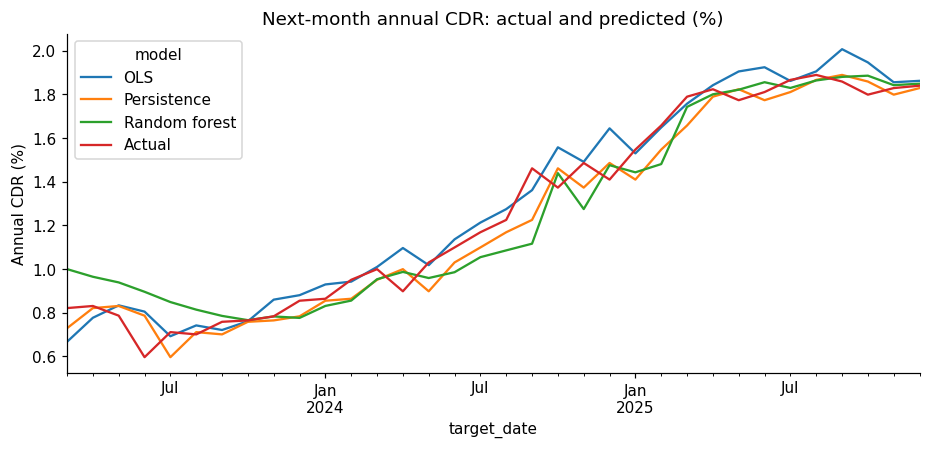

In [10]:
metrics = pd.read_csv(outputs / "model_metrics.csv")
metrics["MAE_bps"] = metrics.mae * 10000
metrics["RMSE_bps"] = metrics.rmse * 10000
display(metrics[["model", "MAE_bps", "RMSE_bps", "observations"]].round(3))
print("Lowest MAE:", metrics.loc[metrics.mae.idxmin(), "model"])
print("Lowest RMSE:", metrics.loc[metrics.rmse.idxmin(), "model"])
wide = predictions.pivot(index="target_date", columns="model", values="predicted")
wide["Actual"] = predictions.groupby("target_date").actual.first()
wide.mul(100).plot(title="Next-month annual CDR: actual and predicted (%)")
plt.ylabel("Annual CDR (%)")
plt.show()

## 10. SQL Server, dashboard and automated reports

The separate SQL Server loader creates primary/foreign keys, validation constraints and a date index, then stages and upserts validated records in a transaction. A live SQL Server is required to verify the adapter. The core notebook uses CSVs and does not imply a database connection has been tested.

Launch the interactive dashboard with `python -m abs_lab.dashboard`. It filters sectors, note seniority and scenarios. Generated research findings and CSVs are available below.

In [11]:
print((ROOT / "reports/executive_summary.md").read_text())

# ABS research brief

**Demonstration only: all securities, prices, macro data and results are simulated.**

## Question
How do credit losses, prepayments and interest rates affect a securitized-credit portfolio, and can allocation constraints reduce measured risk?

## Findings from this run
- The dataset contains 24 notes across 12 pools and 73 month-end snapshots. Validation removed 1 exact duplicate; balances reconcile after principal payments and write-downs.
- Over 48 out-of-sample monthly observations, the illustrative ABS index returned 5.48% annualised with 1.41% volatility. The constrained minimum-variance strategy returned 3.80%, with 0.72% volatility after modelled trading costs.
- The most adverse defined scenario changes the full remaining universe's value by $-17,231,791. This is a repricing scenario, not a probability-weighted loss forecast.
- The lowest forecast MAE belongs to **OLS** at 6.78 basis points of annual CDR. Compare all models against persistence; complexity

## 11. Conclusions and next research steps

- Senior and junior notes exhibit different cash-flow timing and credit-loss exposure.
- Low-volatility allocation is not automatically the best-returning strategy; read concentration and turnover alongside risk.
- The seeded forecast comparison has different MAE and RMSE winners. The simple baseline remains important.
- Simulated results cannot establish real manager skill or predict actual ABS returns.
- Before a real deployment: acquire licensed servicing/pricing data, calibrate legal-deal waterfalls, model delayed recoveries and publication lags, test SQL Server with the target driver, and validate against independent cash-flow/valuation benchmarks.

AI commentary is optional and evidence-constrained; explanatory prose always needs human review.